# 09 · Homologación de platillos y perfil del comensal

**Fase CRISP-DM:** 3. Preparación de los datos

**Objetivo:** dejar listas las dos piezas que el modelo necesita antes de construir las features:

1. **Homologación:** pasar cada nombre del menú ("TACOS DE PASTOR especial") a su **platillo canónico** (`tacos_pastor`). El canónico es lo que se transfiere entre restaurantes: es lo que permite recomendar en un lugar que el comensal nunca visitó.
2. **Perfil del comensal a la fecha:** en cada visita, qué se sabe de la persona **usando solo sus visitas anteriores**.
3. **Perfil de la mesa:** qué se sabe del grupo que se sienta junto (para la lista "para la mesa").

**Dos reglas de producción que se respetan aquí:**

- Las features usan el canónico **predicho**, nunca el verdadero (`config/features.yaml`, `canonical_column`).
- Todo perfil es **punto en el tiempo**: lo que pasa en una visita no puede estar en su propio perfil (fuga de información).

**Entradas:** tablas del contrato; la verdad oculta solo para medir exactitud. **Salidas:** `data/interim/menu_items_homologados.parquet`, `data/interim/perfiles_comensal.parquet`, `data/interim/perfiles_mesa.parquet`.

> Este notebook solo narra el algoritmo. La lógica vive en `src/puzzle_recsys`.

## Configuración

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from puzzle_recsys.catalog.dish_homologation import (
    DishHomologator,
    accuracy_by_group,
    simulate_confirmation,
    split_aliases,
    threshold_table,
    uses_unseen_alias,
)
from puzzle_recsys.config import load_paths, load_simulation, load_yaml
from puzzle_recsys.eda.frames import session_frame
from puzzle_recsys.eda.multivariate import latent_diner_traits
from puzzle_recsys.profiles.diner_profile import (
    COURSES,
    cuisine_prior,
    point_in_time_profiles,
    recovery_by_history,
    visit_events,
)
from puzzle_recsys.profiles.table_profile import table_profile
from puzzle_recsys.repository.parquet_repo import ParquetRepository, run_id_for
from puzzle_recsys.simulation.distributions import make_rng

paths, sim, feat = load_paths(), load_simulation(), load_yaml("features")
hcfg, pcfg = feat["homologation"], feat["profile"]
repo = ParquetRepository(paths.synthetic / run_id_for(sim.run_name, sim.seed))
gt = repo.ground_truth
t = {n: repo.read_table(n) for n in ["restaurants", "menu_items", "canonical_dishes", "canonical_dish_aliases",
                                     "dining_sessions", "guests", "order_items", "diner_profiles"]}
paths.interim.mkdir(parents=True, exist_ok=True)
figs = paths.figures
figs.mkdir(parents=True, exist_ok=True)

## 1. Homologación y su exactitud

### 1.1 Una evaluación honesta: alias que el sistema no conoce

En la simulación, los nombres de los menús se generaron a partir de la **misma lista de alias** de la biblioteca. Si el KNN conociera esa lista completa, encontraría casi siempre una coincidencia exacta: con la lista completa la exactitud fue de **99.9 %**, un número que no dice nada sobre la vida real.

En producción, Puzzle arranca con un catálogo de alias **parcial** y los restaurantes escriben nombres nuevos. Para imitarlo, el KNN solo conoce el **50 %** de los alias (más todos los nombres canónicos); el otro 50 % hace de "nombres que el sistema nunca vio".

In [2]:
canon = t["canonical_dishes"]
canonical_names = canon.set_index("canonical_id")["name"]
aliases = t["canonical_dish_aliases"]
aliases = aliases[aliases["alias"] != aliases["canonical_id"].map(canonical_names)]
known, unseen = split_aliases(aliases, known_share=hcfg["known_alias_share"], rng=make_rng(sim.seed, "alias_split"))
reference = pd.concat([canon[["canonical_id", "name"]], known.rename(columns={"alias": "name"})[["canonical_id", "name"]]])
reference = reference.merge(canon[["canonical_id", "course", "cuisine"]], on="canonical_id")

items = t["menu_items"].merge(t["restaurants"][["restaurant_id", "cuisine_pred"]], on="restaurant_id")
items = items.rename(columns={"cuisine_pred": "cuisine"})
truth = gt.read_table("menu_items").set_index("menu_item_id").reindex(items["menu_item_id"])
items["canonical_true"] = truth["canonical_true"].to_numpy()  # solo para evaluar
variant = truth["name_variant"].to_numpy()
unseen_flag = uses_unseen_alias(items["name"], unseen["alias"].tolist()).to_numpy()
items["tipo_de_nombre"] = np.select(
    [variant == "CANONICAL", variant == "TYPO", unseen_flag],
    ["nombre canónico", "error de dedo", "alias no visto"], "alias visto")
pd.Series({"canónicos": len(canon), "alias conocidos": len(known), "alias no vistos": len(unseen),
           "platillos de menú": len(items)}, name="valor").to_frame().T

,canónicos,alias conocidos,alias no vistos,platillos de menú
valor,220,202,231,36115


### 1.2 El algoritmo

KNN con un vecino sobre **n-gramas de caracteres** (TF-IDF, de 2 a 4 letras) del nombre limpio:

- **Limpieza:** minúsculas, sin acentos ni signos y sin relleno de menú ("especial", "de la casa", "premium"). La lista está en `config/features.yaml`.
- **Mismo tipo de plato:** solo se compara contra canónicos del mismo tipo, porque la carta ya dice si es bebida, entrada, etc.
- **Pista de la cocina:** se suma un peso `w` a los canónicos de la cocina del restaurante ("Ranchera" en una pizzería es una pizza).

**Cómo se elige `w` sin hacer trampa:** los restaurantes se parten al azar en dos mitades. `w` se elige en la mitad de **ajuste** y la exactitud se reporta en la otra mitad, la de **prueba**, que no participó en la elección.

In [3]:
restaurants = items["restaurant_id"].unique()
tune_ids = set(make_rng(sim.seed, "homologation_split").choice(restaurants, len(restaurants) // 2, replace=False))
is_tune = items["restaurant_id"].isin(tune_ids).to_numpy()

grid = []
for w in hcfg["cuisine_weight_grid"]:
    model = DishHomologator(stop_words=hcfg["stop_words"], cuisine_weight=w).fit(reference)
    pred = model.predict(items[is_tune])
    hit = pred["canonical_pred"].to_numpy() == items.loc[is_tune, "canonical_true"].to_numpy()
    unseen_hit = hit[items.loc[is_tune, "tipo_de_nombre"].to_numpy() == "alias no visto"]
    grid.append({"w": w, "exactitud (ajuste)": hit.mean(), "alias no vistos (ajuste)": unseen_hit.mean()})
grid = pd.DataFrame(grid)
w_best = float(grid.loc[grid["exactitud (ajuste)"].idxmax(), "w"])
display(grid.round(4))
pd.Series({"w elegido": w_best}).to_frame("valor").T

,w,exactitud (ajuste),alias no vistos (ajuste)
0,0.0,0.9119,0.7332
1,0.1,0.9309,0.7850
2,0.2,0.9384,0.8099
3,0.3,0.9377,0.8097
4,0.5,0.9173,0.7823


,w elegido
valor,0.2


In [4]:
model = DishHomologator(stop_words=hcfg["stop_words"], cuisine_weight=w_best).fit(reference)
pred = model.predict(items)
items["canonical_knn"] = pred["canonical_pred"].to_numpy()
items["confianza"] = pred["confianza"].to_numpy()
test = items[~is_tune]
accuracy_by_group(test["canonical_knn"], test["canonical_true"], test["tipo_de_nombre"]).round(4)

,grupo,n,exactitud
0,alias no visto,5704,0.7942
1,alias visto,3998,0.9997
2,error de dedo,1091,0.9890
3,nombre canónico,7164,0.9994
4,total,17957,0.9337


### 1.3 La confianza sirve para saber cuándo preguntar

Si la similitud del nombre con su vecino es baja, la sugerencia es poco fiable. Esta tabla responde: si solo se aceptaran automáticamente las sugerencias con confianza mayor o igual al umbral, ¿qué fracción del menú se cubre y con qué exactitud? Lo que queda debajo del umbral es lo que conviene **pedirle al restaurante que confirme primero**.

,umbral,cobertura,exactitud
0,0.3,0.983,0.944
1,0.5,0.943,0.965
2,0.7,0.825,0.986
3,0.9,0.645,0.997


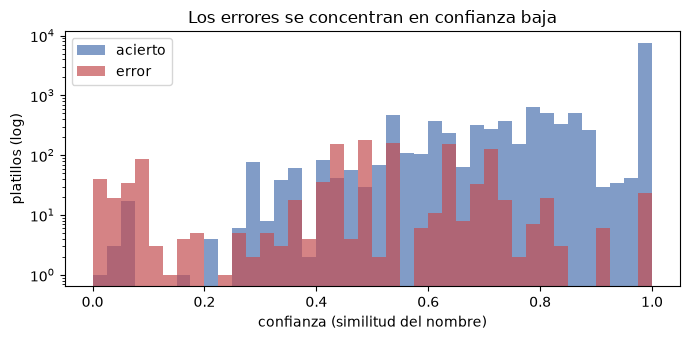

In [5]:
hit_test = pd.Series(test["canonical_knn"].to_numpy() == test["canonical_true"].to_numpy())
display(threshold_table(test["confianza"].reset_index(drop=True), hit_test, hcfg["confidence_thresholds"]).round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(0, 1, 41)
ax.hist(test.loc[hit_test.to_numpy(), "confianza"], bins=bins, alpha=0.7, label="acierto", color="#4C72B0")
ax.hist(test.loc[~hit_test.to_numpy(), "confianza"], bins=bins, alpha=0.7, label="error", color="#C44E52")
ax.set_yscale("log"); ax.set_xlabel("confianza (similitud del nombre)"); ax.set_ylabel("platillos (log)")
ax.set_title("Los errores se concentran en confianza baja"); ax.legend()
fig.tight_layout()
fig.savefig(figs / "09_confianza_homologacion.png", dpi=150)

In [6]:
# Errores típicos en alias no vistos (para entender qué falla).
errores = test[(test["tipo_de_nombre"] == "alias no visto") & (test["canonical_knn"] != test["canonical_true"])]
errores.drop_duplicates("name").sample(12, random_state=sim.seed)[["name", "cuisine", "canonical_true", "canonical_knn", "confianza"]].round(2)

,name,cuisine,canonical_true,canonical_knn,confianza
17213,Guajolota especial,antojitos,tamal,tlacoyos,0.09
11195,Nieve de la casa,mexicana,helado,churros,0.01
27695,BOTELLA DE AGUA PREMIUM,tacos_tortas,agua_natural,agua_fresca,0.63
8251,VINO TINTO ARGENTINO,mexicana,copa_malbec,copa_vino,0.45
25841,PIZZA JAMÓN Y PIÑA,pizza,pizza_hawaiana,pizza_mexicana,0.41
26348,Hamburguesa de garbanzo,hamburguesas,hamburguesa_veggie,hamburguesa_clasica,0.69
22891,Tacos dorados de pollo,cafeteria,flautas_pollo,tacos_bistec,0.44
53,Nuggets,mexicana,tiras_pollo,pechuga_plancha,0.06
17227,Hamburguesa BBQ estilo chef,antojitos,hamburguesa_tocino,hamburguesa_clasica,0.83
20750,Lasaña bolognesa,tacos_tortas,lasagna,bolognesa,0.80


### 1.4 La confirmación del restaurante

En Puzzle el canónico se **sugiere** y el restaurante lo confirma o corrige (`canonicalSource` = `CONFIRMED` / `MANUAL`; ver `docs/cambios-base-de-datos.md`). Se simula que el **70 %** de los restaurantes revisa su menú completo (`supply.canonical_confirmation_rate`). Los demás se quedan con la sugerencia (`SUGGESTED`). Este es el canónico que usan las features de aquí en adelante.

In [7]:
conf = simulate_confirmation(items["canonical_knn"], items["canonical_true"], items["restaurant_id"],
                             rate=sim.supply["canonical_confirmation_rate"], rng=make_rng(sim.seed, "confirmation"))
items["canonical_pred"] = conf["canonical_pred"].to_numpy()
items["canonical_source"] = conf["canonical_source"].to_numpy()
display(items["canonical_source"].value_counts(normalize=True).mul(100).round(1).rename("% de platillos").to_frame().T)
accuracy_by_group(items["canonical_pred"], items["canonical_true"], items["canonical_source"]).round(4)

canonical_source,CONFIRMED,SUGGESTED,MANUAL
% de platillos,65.1,30.4,4.5


,grupo,n,exactitud
0,CONFIRMED,23521,1.0000
1,MANUAL,1609,1.0000
2,SUGGESTED,10985,0.9363
3,total,36115,0.9806


In [8]:
out = items[["menu_item_id", "canonical_pred", "confianza", "canonical_source"]]
out.to_parquet(paths.interim / "menu_items_homologados.parquet", index=False)
f"{len(out):,} platillos guardados en data/interim/menu_items_homologados.parquet"

'36,115 platillos guardados en data/interim/menu_items_homologados.parquet'

## 2. Perfil del comensal (punto en el tiempo)

Para cada visita de cada comensal registrado se calcula su perfil **antes** de esa visita: suma acumulada de sus visitas anteriores, **menos la visita actual**.

| Parte del perfil | Qué es |
|---|---|
| `afinidad__<cocina>` | Proporción **suavizada** de visitas a cada cocina: `(visitas a c + s·prior_c) / (visitas + s)`, con `s = 3` |
| Prior (arranque en frío) | Proporción de restaurantes de cada cocina, mezclada 50/50 con las cocinas declaradas en el onboarding |
| `habito__<tipo>` | Líneas propias por visita de cada tipo de plato |
| `picante_medio`, `log_ticket_medio`, `tasa_compartir` | Promedios de las visitas anteriores |
| `visitas_previas`, `dias_desde_ultima` | Cuánta historia hay |

**Por qué el prior usa la proporción de restaurantes y no la de visitas:** la proporción de visitas se calcula con todo el año, que incluye el futuro de cada visita. La proporción de restaurantes viene del DENUE y no depende de ninguna visita.

In [9]:
mesas = session_frame(t["dining_sessions"], t["order_items"], t["restaurants"], t["menu_items"], sim.calendar["timezone"])
mesas = mesas.merge(t["dining_sessions"][["session_id", "opened_at"]], on="session_id")
events = visit_events(mesas, t["guests"], t["order_items"], t["menu_items"])
cuisines = sorted(t["restaurants"]["cuisine_pred"].unique())
share = t["restaurants"]["cuisine_pred"].value_counts(normalize=True).reindex(cuisines, fill_value=0)
prior = cuisine_prior(t["diner_profiles"], share, declared_weight=pcfg["declared_weight"])
perfiles = point_in_time_profiles(events, cuisines=cuisines, prior=prior, prior_strength=pcfg["prior_strength"])
pd.Series({"visitas de comensales registrados": len(perfiles), "comensales": perfiles["diner_id"].nunique(),
           "columnas del perfil": perfiles.shape[1] - 3,
           "% de visitas sin historia (arranque en frío)": f"{(perfiles['visitas_previas'] == 0).mean():.1%}"},
          name="valor").to_frame().T

,visitas de comensales registrados,comensales,columnas del perfil,% de visitas sin historia (arranque en frío)
valor,746736,20203,30,2.7%


### 2.1 Verificación de que no hay fuga

La prueba unitaria `test_profile_does_not_change_when_the_current_visit_changes` ya garantiza que cambiar una visita no altera su propio perfil. Aquí se comprueba sobre los datos reales que cada perfil cuenta exactamente las visitas anteriores.

In [10]:
orden = perfiles.sort_values(["diner_id", "opened_at"])
esperado = orden.groupby("diner_id").cumcount()
chequeos = {
    "visitas_previas = visitas anteriores (ordenadas por fecha)": bool((orden["visitas_previas"] == esperado).all()),
    "primera visita sin días desde la anterior": bool(orden.loc[esperado == 0, "dias_desde_ultima"].isna().all()),
    "afinidad suma 1 en cada visita": bool(np.allclose(perfiles.filter(like="afinidad__").sum(axis=1), 1)),
}
pd.Series(chequeos, name="¿se cumple?").to_frame()

,¿se cumple?
visitas_previas = visitas anteriores (ordenadas por fecha),True
primera visita sin días desde la anterior,True
afinidad suma 1 en cada visita,True


### 2.2 ¿Cuánta historia hace falta? (contra la verdad oculta)

Cada rasgo del perfil se compara con el gusto latente que debería reflejar, separando por cuántas visitas previas había. Así se ve la **curva de aprendizaje** del perfil: con 0 visitas solo está el onboarding, y con más visitas el perfil se acerca al gusto real.

visitas_previas,0,1-2,3-5,6-10,11-20,21+
observado,,,,,,
afinidad__cafeteria,0.52,0.51,0.53,0.55,0.59,0.70
afinidad__mexicana,0.36,0.42,0.47,0.52,0.58,0.72
afinidad__tacos_tortas,0.53,0.52,0.55,0.59,0.63,0.71
habito__DESSERT,NaN,0.35,0.52,0.64,0.74,0.83
habito__DRINK,NaN,0.38,0.55,0.68,0.79,0.89
habito__STARTER,NaN,0.41,0.58,0.71,0.80,0.90
picante_medio,NaN,0.14,0.24,0.30,0.36,0.42
tasa_compartir,NaN,0.13,0.20,0.28,0.37,0.51


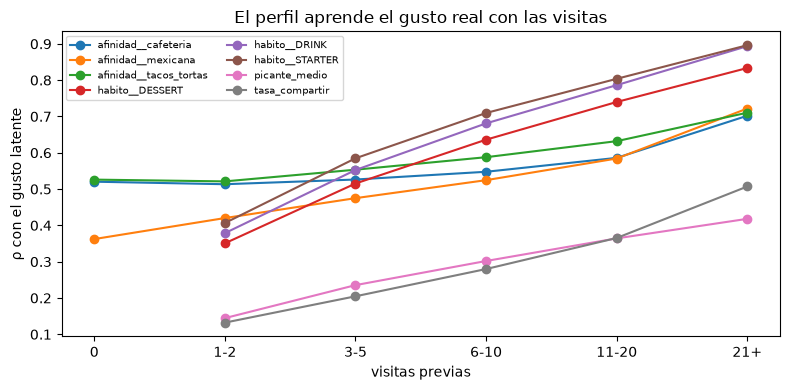

In [11]:
ids = pd.Index(perfiles["diner_id"].unique())
latent = latent_diner_traits(gt.read_table("diner_tastes"), gt.read_table("duplicate_accounts"), ids, cuisines)
aff = pd.DataFrame(np.vstack(latent["cuisine_affinity"].to_numpy()), index=ids, columns=cuisines)
truth_traits = latent[["spice_tolerance", "sharer", "habit_starter", "habit_dessert", "habit_drink"]].join(
    aff[["mexicana", "tacos_tortas", "cafeteria"]].add_prefix("afinidad_latente__"))
pairs = [
    ("afinidad__mexicana", "afinidad_latente__mexicana"),
    ("afinidad__tacos_tortas", "afinidad_latente__tacos_tortas"),
    ("afinidad__cafeteria", "afinidad_latente__cafeteria"),
    ("habito__STARTER", "habit_starter"),
    ("habito__DESSERT", "habit_dessert"),
    ("habito__DRINK", "habit_drink"),
    ("picante_medio", "spice_tolerance"),
    ("tasa_compartir", "sharer"),
]
curva = recovery_by_history(perfiles, truth_traits, pairs, bins=[0, 1, 3, 6, 11, 21, np.inf])
tabla = curva.pivot(index="observado", columns="visitas_previas", values="rho")
display(tabla.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
for obs, row in tabla.iterrows():
    ax.plot(range(len(row)), row.to_numpy(), marker="o", label=obs)
ax.set_xticks(range(len(tabla.columns)), [str(c) for c in tabla.columns])
ax.set_xlabel("visitas previas"); ax.set_ylabel("ρ con el gusto latente")
ax.set_title("El perfil aprende el gusto real con las visitas"); ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(figs / "09_curva_perfil.png", dpi=150)

In [12]:
perfiles.to_parquet(paths.interim / "perfiles_comensal.parquet", index=False)
f"{len(perfiles):,} perfiles guardados en data/interim/perfiles_comensal.parquet"

'746,736 perfiles guardados en data/interim/perfiles_comensal.parquet'

## 3. Perfil de la mesa

Para la lista "para la mesa" importa el grupo, no la persona. Por mesa se calcula:

- **Personas y cuántas tienen perfil:** los acompañantes anónimos no tienen historia. En una mesa con pocos perfiles conocidos el modelo debe apoyarse más en la popularidad.
- **Gusto por compartir de la mesa:** promedio y máximo de la `tasa_compartir` a la fecha de quienes tienen perfil. Desde la corrección 8 (notebook 08), quien comparte empuja a la mesa a compartir.
- **Alergias:** la **unión** de las declaradas. Un platillo con el alérgeno de cualquiera se filtra **antes** del modelo, que no decide sobre seguridad alimentaria.

Las reglas de agregación de gustos (promedio y miseria mínima, con `w = 0.3`) se aplican en el notebook 10, platillo por platillo, porque dependen de cada candidato.

In [13]:
alergias = t["diner_profiles"].set_index("diner_id")["declared_allergies"].map(list)
mesa = table_profile(t["guests"], perfiles[["session_id", "diner_id", "tasa_compartir"]], alergias)
display(mesa[["personas", "con_perfil", "pct_con_perfil", "tasa_compartir_media", "tasa_compartir_max"]].describe().T.round(3))
pd.Series({
    "mesas": len(mesa),
    "% de mesas con al menos una alergia declarada": f"{(mesa['alergias'].map(len) > 0).mean():.1%}",
    "% de mesas sin ningún perfil": f"{(mesa['con_perfil'] == 0).mean():.1%}",
}, name="valor").to_frame().T

,count,mean,std,min,25%,50%,75%,max
personas,512907.0,2.872,1.667,1.000,2.000,2.000,4.000,30.0
con_perfil,512907.0,1.456,0.713,1.000,1.000,1.000,2.000,13.0
pct_con_perfil,512907.0,0.597,0.271,0.062,0.400,0.500,1.000,1.0
tasa_compartir_media,502052.0,0.255,0.141,0.000,0.175,0.250,0.323,1.0
tasa_compartir_max,502052.0,0.286,0.163,0.000,0.192,0.273,0.364,1.0


,mesas,% de mesas con al menos una alergia declarada,% de mesas sin ningún perfil
valor,512907,8.3%,0.0%


In [14]:
# ¿El gusto por compartir A LA FECHA ya separa las mesas que comparten? (solo mesas de 2+ con historia)
shared = set(t["order_items"].loc[t["order_items"]["is_shared"], "session_id"])
m = mesa[(mesa["personas"] >= 2) & mesa["tasa_compartir_media"].notna()].copy()
m["comparte"] = m["session_id"].isin(shared)
m["tercil"] = pd.qcut(m["tasa_compartir_media"].rank(method="first"), 3, labels=["bajo", "medio", "alto"])
m.groupby("tercil", observed=True).agg(mesas=("comparte", "size"), tasa_media=("tasa_compartir_media", "mean"),
                                       pct_comparten=("comparte", "mean")).assign(pct_comparten=lambda d: 100 * d["pct_comparten"]).round(3)

,mesas,tasa_media,pct_comparten
tercil,,,
bajo,139174,0.123,22.528
medio,139173,0.247,26.768
alto,139173,0.396,31.307


In [15]:
mesa.to_parquet(paths.interim / "perfiles_mesa.parquet", index=False)
f"{len(mesa):,} mesas guardadas en data/interim/perfiles_mesa.parquet"

'512,907 mesas guardadas en data/interim/perfiles_mesa.parquet'

## Conclusiones

### 1. Homologación: 93 % sin ayuda y 98 % con la confirmación del restaurante

- **La primera medición engañaba.** Con la lista completa de alias, la exactitud fue de 99.9 %, porque los nombres simulados salieron de esa misma lista. La evaluación honesta deja que el KNN conozca solo la mitad de los alias, y la otra mitad hace de nombres nuevos.
- **Exactitud en los restaurantes de prueba**, que no participaron en elegir `w`:

| Tipo de nombre | Exactitud |
|---|---|
| Nombre canónico | 99.9 % |
| Alias ya conocido | 99.97 % |
| Error de dedo | 98.9 % |
| **Alias nunca visto** | **79.4 %** |
| Total | 93.4 % |

- **La pista de la cocina del restaurante** (`w = 0.2`, elegido en la mitad de ajuste) sube los alias nunca vistos de 73 % a 81 % en la mitad de ajuste. Un peso mayor empeora, porque empieza a ignorar el nombre.
- **Los errores son de vocabulario, no de ortografía:** "Guajolota" → tamal, "Nieve" → helado, "Nuggets" → tiras de pollo. Son sinónimos sin letras en común. Ningún método de n-gramas los resuelve; los resuelve el **catálogo de alias**, que crece con cada confirmación.
- **La confianza sirve:** si solo se aceptan sugerencias con confianza ≥ 0.7, se cubre el 83 % del menú con 98.6 % de exactitud. Debajo de ese umbral conviene **pedirle al restaurante que confirme primero**.
- **Con la confirmación simulada** (70 % de los restaurantes revisa su menú): 65 % de los platillos quedan `CONFIRMED`, 4.5 % `MANUAL` y 30 % `SUGGESTED`. La exactitud final del canónico es de **98.1 %**. Las features usan este canónico, con un 2 % de error, como pasaría en producción.

### 2. Perfil del comensal a la fecha: sin fuga, y aprende con las visitas

- **746,736 perfiles**, uno por visita de cada comensal registrado. Los chequeos confirman que cada perfil cuenta exactamente las visitas anteriores, y la prueba unitaria de fuga confirma que la visita actual no altera su propio perfil.
- **Curva de aprendizaje** (ρ con el gusto latente):

| Rasgo | 1-2 visitas previas | 6-10 | 21+ |
|---|---|---|---|
| Hábito de entrada | 0.41 | 0.71 | 0.90 |
| Hábito de bebida | 0.38 | 0.68 | 0.89 |
| Hábito de postre | 0.35 | 0.64 | 0.83 |
| Afinidad por mexicana | 0.42 | 0.52 | 0.72 |
| Tasa de compartir | 0.13 | 0.28 | 0.51 |
| Picante pedido | 0.14 | 0.30 | 0.42 |

- **El onboarding ayuda en la primera visita:** con 0 visitas, la afinidad por cocina ya tiene ρ = 0.36 a 0.53 con el gusto latente, solo por el prior (población + cocinas declaradas).
- **Lo que tarda más:** picante y compartir necesitan más de 10 visitas para ser confiables, porque cada visita aporta poca información sobre ellos.
- **Ojo con el arranque en frío:** en la simulación solo el 2.7 % de las visitas no tiene historia, porque se simula un año completo. Al **lanzar** la app será casi el 100 %. Por eso el modelo debe evaluarse **por tramos de historia** (notebook 13), no solo en promedio.

### 3. Perfil de la mesa

- En promedio, el **60 %** de las personas de una mesa tiene perfil; el resto son acompañantes anónimos.
- El **8.3 %** de las mesas tiene al menos una alergia declarada: esos platillos se filtran antes del modelo.
- **El gusto por compartir a la fecha ya separa las mesas:** del tercil bajo al alto, la proporción de mesas que comparte va de 23 % a 31 %. Es menos que el 15 % → 38 % del notebook 08, que usaba el gusto **latente** de todos los sentados. Aquí solo se conoce la historia de los registrados, que es lo que tendrá el modelo.
- Todas las mesas tienen al menos un perfil, porque la simulación parte del comensal registrado que abre la mesa. En Puzzle habrá mesas sin ningún registrado; esas usan solo popularidad.

**Pasa al notebook 10:** features por candidato (platillo × persona y platillo × mesa) con el canónico predicho, los perfiles a la fecha y la agregación promedio + miseria mínima; partición temporal.
